# 279. Dark proteins kmerseek puts a region on, at E < 1 and E < 10

**Question.** A protein is *dark* when phmmer, jackhmmer (3 iterations) and mmseqs2 all fail
to find a hit for it in Swiss-Prot with the query species' own clade removed. For each
kmerseek alphabet and k-size, what share of the dark proteins does kmerseek put a region on,
and how does that compare with the share of *placed* proteins (every protein that is not
dark) it puts a region on?

Both questions use one E-value cutoff for everything, as Olga asked on 2026-10-12: a protein
is dark at cutoff E when no tool has a hit with E-value below E, and kmerseek *reaches* a
protein at cutoff E when one of its regions has an E-value below E. The cutoffs are set in
the first code cell; change them there and re-run to try others. Nothing is searched again.

**How to read it.** Reaching a protein is not the same as finding its homolog: at E < 10
chance alone puts a region on most proteins. So a setting's dark share means something only
next to its placed share. Placed proteins have a homolog in the reference, so a setting that
finds homologs reaches them more often than dark ones. A setting that reaches both at the
same rate is reporting something for everything.

**Decision.** Whether the dark set has candidates worth the structure check (the expensive
next step of the dark-set pipeline), and at which cutoff. The rule, written before the E < 1
and E < 10 kmerseek numbers were computed:

* A setting *tells dark from placed* when its placed share is at least twice its dark share.
* At a cutoff, the dark set has candidates if, in **all five species**, at least one setting
  that tells dark from placed reaches **at least 5%** of the dark proteins.
* If yes, we take the dark proteins those settings reach to the structure check. If no, the
  dark-set claim has no candidates at that cutoff.

The E-value cutoff of 0.01 was looked at before this rule was written (median dark share
about 0, best setting 6-9%, under the pipeline's dark set at E <= 0.001).

**Data.** The invertebrate dark-set midi run (`runs/ladder-0.4-midi`, finished 2026-10-12
13:04 on Sherlock; [PR 57](https://github.com/seanome/2024-kmerseek-analysis/pull/57),
commit e3808d1), image `olgabot/kmerseek:0.4.0-rc5`.

* Queries: five proteomes. Human (UniProt UP000005640), worm *C. elegans* (UP000001940),
  yeast *S. cerevisiae* S288C (UP000002311), *Borreliella burgdorferi* B31 (UP000001807) and
  *Botryllus schlosseri* (gene models, 45_339 proteins).
* Target: reviewed Swiss-Prot with the query's clade removed: Mammalia, Chromadorea,
  Saccharomycetes, Spirochaetia and Ascidiacea.
* kmerseek: 115 alphabet and k-size pairs (every other k from notebook 274's k_min to k_max,
  minus the pairs dropped in PR 57), at scaled 1 and 10, each extended through mismatches at
  its alphabet's own mismatch penalty, so every region has a Karlin-Altschul E-value.
  Settings whose index holds no Karlin-Altschul fit have no E-values and are left out.
* The per-protein tables come from `tools/export-protein-evalues` (PR 57, commit ac5e4f9),
  which reads the run's own files: each protein's smallest hit E-value per tool (the tools
  ran with a reporting cutoff of E = 10, so every hit below 10 is there) and its smallest
  kmerseek region E-value per setting.
* The low-complexity mask was off for every kmerseek search in this run.

In [1]:
# The toggle. Each pair is (cutoff for the tools that define dark, cutoff for kmerseek).
# A protein counts below a cutoff when its E-value is strictly less than it.
CUTOFF_PAIRS = [(1, 1), (10, 10)]
SCALED = 1  # 1 or 10: which kmerseek index setting to draw
MIN_PLACED_OVER_DARK = 2  # "tells dark from placed": placed share >= 2 x dark share
MIN_DARK_SHARE = 0.05  # "has candidates": at least 5% of dark proteins reached

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, str(Path.cwd()))
import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_tbl_cols(-1)

DATA = Path("/Users/olga/data/invertebrate-dark-set/results-0.4/protein-evalues")
FIG = Path("../figures")
TABLES = Path("../tables")
SPECIES = ["human", "worm", "yeast", "borrelia", "botryllus"]
SPECIES_NAME = {
    "human": "Human",
    "worm": "C. elegans",
    "yeast": "S. cerevisiae",
    "borrelia": "B. burgdorferi",
    "botryllus": "B. schlosseri",
}
TOOLS = ["phmmer", "jackhmmer", "mmseqs2"]

missing = [
    s for s in SPECIES if not (DATA / f"{s}_protein_tool_min_evalue.csv.gz").exists()
]
if missing:
    raise SystemExit(
        f"Copy the export for {missing} from Sherlock into {DATA} first "
        "(see tools/export-protein-evalues on PR 57)."
    )

tool = pl.concat(
    [
        pl.read_csv(
            DATA / f"{s}_protein_tool_min_evalue.csv.gz", infer_schema_length=0
        ).with_columns(pl.col(TOOLS).cast(pl.Float64), pl.lit(s).alias("species"))
        for s in SPECIES
    ]
)
# Smallest E-value over the three tools; null when no tool reported any hit
tool = tool.with_columns(pl.min_horizontal(TOOLS).alias("best_tool_evalue"))
km = pl.concat(
    [
        pl.read_csv(
            DATA / f"{s}_protein_kmerseek_min_evalue.csv.gz",
            schema_overrides={"accession": pl.String},
        ).with_columns(pl.lit(s).alias("species"))
        for s in SPECIES
    ]
)
unfitted = pl.concat(
    [
        pl.read_csv(DATA / f"{s}_kmerseek_unfitted.csv").with_columns(
            pl.lit(s).alias("species")
        )
        for s in SPECIES
    ]
)
print(
    tool.group_by("species")
    .agg(
        pl.len().alias("proteins"),
        pl.col("best_tool_evalue").is_null().sum().alias("no_tool_hit_at_all"),
    )
    .sort(pl.col("species").replace_strict({s: i for i, s in enumerate(SPECIES)}))
)
print(
    km.group_by("species", "scaled")
    .agg(
        pl.struct("alphabet", "ksize").n_unique().alias("settings_with_evalues"),
        pl.len().alias("protein_setting_rows"),
    )
    .sort("species", "scaled")
)
print(
    unfitted.filter(pl.col("scaled") == SCALED)
    .group_by("species")
    .agg(pl.len().alias(f"settings_without_fit_scaled_{SCALED}"))
)

┌───────────┬──────────┬────────────────────┐
│ species   ┆ proteins ┆ no_tool_hit_at_all │
│ ---       ┆ ---      ┆ ---                │
│ str       ┆ u32      ┆ u32                │
╞═══════════╪══════════╪════════════════════╡
│ human     ┆ 20600    ┆ 303                │
│ worm      ┆ 19819    ┆ 481                │
│ yeast     ┆ 6049     ┆ 83                 │
│ borrelia  ┆ 1291     ┆ 17                 │
│ botryllus ┆ 45339    ┆ 876                │
└───────────┴──────────┴────────────────────┘
┌───────────┬────────┬───────────────────────┬──────────────────────┐
│ species   ┆ scaled ┆ settings_with_evalues ┆ protein_setting_rows │
│ ---       ┆ ---    ┆ ---                   ┆ ---                  │
│ str       ┆ i64    ┆ u32                   ┆ u32                  │
╞═══════════╪════════╪═══════════════════════╪══════════════════════╡
│ borrelia  ┆ 1      ┆ 89                    ┆ 103562               │
│ borrelia  ┆ 10     ┆ 85                    ┆ 71578                │
│ bo

## 1. How many proteins are dark at each cutoff

A protein is dark at cutoff E when none of phmmer, jackhmmer and mmseqs2 has a hit for it
with an E-value below E. A larger cutoff accepts weaker hits, so fewer proteins stay dark.
The pipeline's own dark set used E <= 0.001; it is drawn for comparison. Here the cutoff is
strict (E < 0.001), so a protein whose best hit is exactly E = 0.001 is dark here and placed
in the pipeline: that is one protein in human (3_103 here, 3_102 there) and one in
*B. schlosseri* (20_449 against 20_448).

┌───────────┬─────────────┬──────────┬───────┬────────────┐
│ species   ┆ tool_cutoff ┆ proteins ┆ dark  ┆ dark_share │
│ ---       ┆ ---         ┆ ---      ┆ ---   ┆ ---        │
│ str       ┆ f64         ┆ u32      ┆ u32   ┆ f64        │
╞═══════════╪═════════════╪══════════╪═══════╪════════════╡
│ human     ┆ 0.001       ┆ 20600    ┆ 3103  ┆ 0.151      │
│ human     ┆ 1.0         ┆ 20600    ┆ 1696  ┆ 0.082      │
│ human     ┆ 10.0        ┆ 20600    ┆ 442   ┆ 0.021      │
│ worm      ┆ 0.001       ┆ 19819    ┆ 8915  ┆ 0.45       │
│ worm      ┆ 1.0         ┆ 19819    ┆ 4667  ┆ 0.235      │
│ worm      ┆ 10.0        ┆ 19819    ┆ 798   ┆ 0.04       │
│ yeast     ┆ 0.001       ┆ 6049     ┆ 1299  ┆ 0.215      │
│ yeast     ┆ 1.0         ┆ 6049     ┆ 725   ┆ 0.12       │
│ yeast     ┆ 10.0        ┆ 6049     ┆ 157   ┆ 0.026      │
│ borrelia  ┆ 0.001       ┆ 1291     ┆ 612   ┆ 0.474      │
│ borrelia  ┆ 1.0         ┆ 1291     ┆ 292   ┆ 0.226      │
│ borrelia  ┆ 10.0        ┆ 1291     ┆ 5

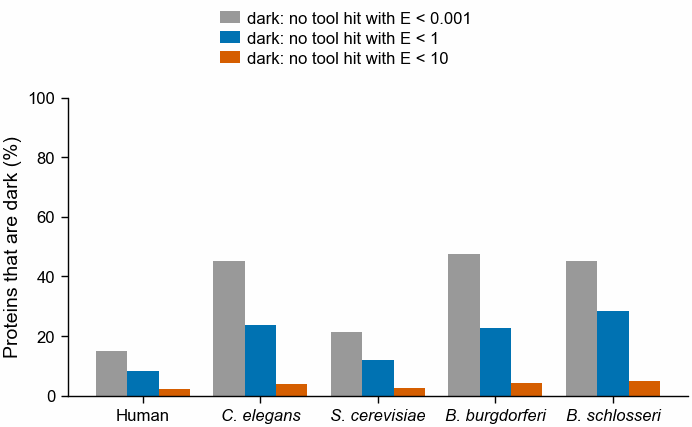

In [3]:
def dark_flags(tool_cutoff):
    # True when no tool hit has E < tool_cutoff
    return tool.select(
        "species",
        "accession",
        (
            pl.col("best_tool_evalue").is_null()
            | (pl.col("best_tool_evalue") >= tool_cutoff)
        ).alias("dark"),
    )


tool_cutoffs = sorted({0.001, *(t for t, _ in CUTOFF_PAIRS)})
dark_counts = pl.concat(
    [
        dark_flags(t)
        .group_by("species")
        .agg(pl.len().alias("proteins"), pl.col("dark").sum().alias("dark"))
        .with_columns(pl.lit(t).cast(pl.Float64).alias("tool_cutoff"))
        for t in tool_cutoffs
    ]
).with_columns((pl.col("dark") / pl.col("proteins")).alias("dark_share"))
order = {s: i for i, s in enumerate(SPECIES)}
dark_counts = dark_counts.sort(pl.col("species").replace_strict(order), "tool_cutoff")
print(
    dark_counts.select(
        "species", "tool_cutoff", "proteins", "dark", pl.col("dark_share").round(3)
    )
)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55)
colours = [
    pf.GREY,
    pf.OKABE_ITO["blue"],
    pf.OKABE_ITO["vermillion"],
    pf.OKABE_ITO["bluish_green"],
]
width = 0.8 / len(tool_cutoffs)
for j, t in enumerate(tool_cutoffs):
    d = dark_counts.filter(pl.col("tool_cutoff") == t)
    xs = [order[s] + (j - (len(tool_cutoffs) - 1) / 2) * width for s in d["species"]]
    ax.bar(
        xs,
        100 * d["dark_share"],
        width=width,
        color=colours[j % len(colours)],
        label=f"dark: no tool hit with E < {t:g}",
    )
ax.set_xticks(range(len(SPECIES)), [SPECIES_NAME[s] for s in SPECIES])
for lab in ax.get_xticklabels():
    lab.set_fontstyle("italic" if lab.get_text() != "Human" else "normal")
ax.set_ylabel("Proteins that are dark (%)")
ax.set_ylim(0, 100)
pf.shared_legend(fig, ncol=1)
pf.save(fig, FIG / "279_dark_share_by_tool_evalue_qfo_swissprot")

## 2. Share of dark and of placed proteins each kmerseek setting reaches

One panel per species (columns) and per cutoff pair (rows). Each point is one kmerseek
alphabet and k-size at the chosen `SCALED`. x: share of the placed proteins it puts a region
on with E below the cutoff. y: the same for the dark proteins. A point on the grey diagonal
reaches dark and placed proteins equally often, so it does not tell them apart. The dashed
line is placed share = 2 x dark share: points below it tell dark from placed under this
notebook's rule. Points high on the y-axis and below the dashed line are the candidates.

Three settings with the largest dark share, per species and cutoff:
┌─────────────┬─────────────────┬───────────┬──────────────────────────┬───────┬───────────────┬──────────────┬────────────┬─────────────────┬────────────────┬──────────────┬────────────────────────┐
│ tool_cutoff ┆ kmerseek_cutoff ┆ species   ┆ alphabet                 ┆ ksize ┆ dark_proteins ┆ dark_reached ┆ dark_share ┆ placed_proteins ┆ placed_reached ┆ placed_share ┆ tells_dark_from_placed │
│ ---         ┆ ---             ┆ ---       ┆ ---                      ┆ ---   ┆ ---           ┆ ---          ┆ ---        ┆ ---             ┆ ---            ┆ ---          ┆ ---                    │
│ f64         ┆ f64             ┆ str       ┆ str                      ┆ i64   ┆ u32           ┆ u32          ┆ f64        ┆ u32             ┆ u32            ┆ f64          ┆ bool                   │
╞═════════════╪═════════════════╪═══════════╪══════════════════════════╪═══════╪═══════════════╪══════════════╪════════════╪════════

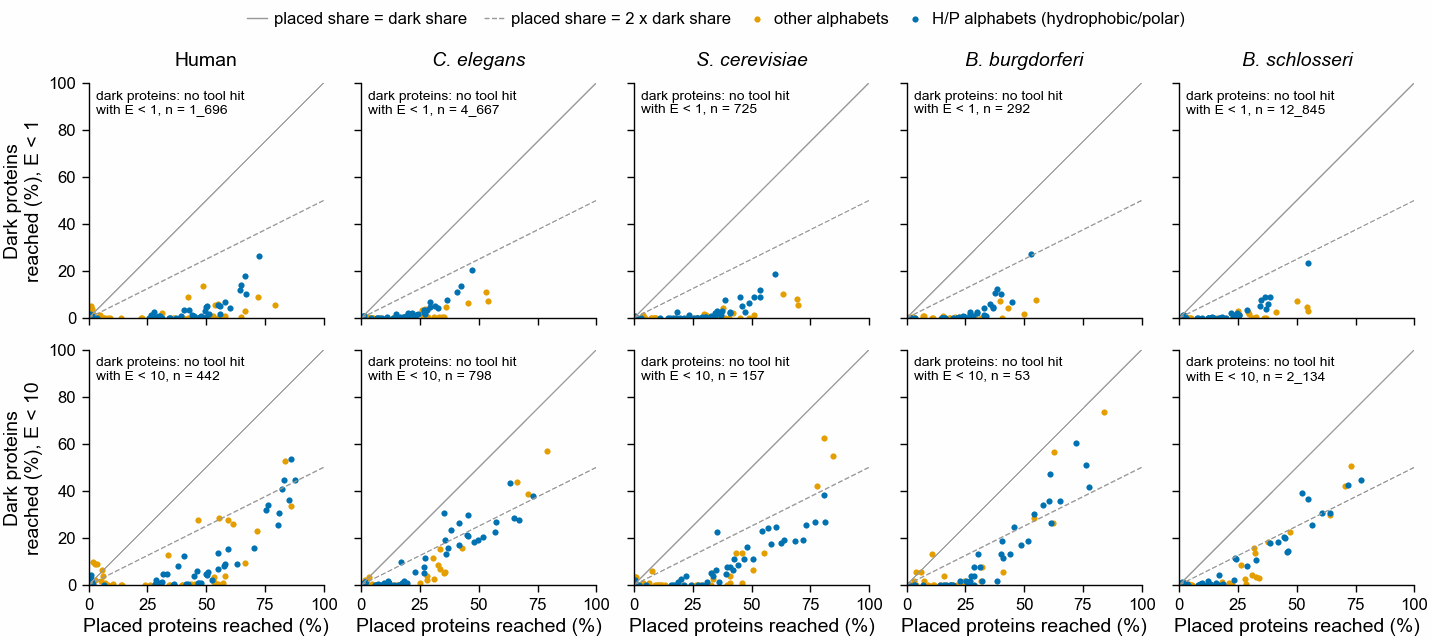

In [4]:
def reach(tool_cutoff, km_cutoff, scaled=SCALED):
    # Per species and setting: dark and placed proteins, and how many of each kmerseek reaches
    flags = dark_flags(tool_cutoff)
    sizes = flags.group_by("species").agg(
        pl.col("dark").sum().alias("dark_proteins"),
        (~pl.col("dark")).sum().alias("placed_proteins"),
    )
    hit = km.filter(
        (pl.col("scaled") == scaled) & (pl.col("min_region_evalue") < km_cutoff)
    ).join(flags, on=["species", "accession"], how="left")
    if hit["dark"].null_count():
        raise ValueError("kmerseek reached a protein that is not in the tool table")
    settings = (
        km.filter(pl.col("scaled") == scaled)
        .select("species", "alphabet", "ksize")
        .unique()
    )
    counts = hit.group_by("species", "alphabet", "ksize").agg(
        pl.col("dark").sum().alias("dark_reached"),
        (~pl.col("dark")).sum().alias("placed_reached"),
    )
    out = (
        settings.join(counts, on=["species", "alphabet", "ksize"], how="left")
        .with_columns(pl.col("dark_reached", "placed_reached").fill_null(0))
        .join(sizes, on="species")
        .with_columns(
            (pl.col("dark_reached") / pl.col("dark_proteins")).alias("dark_share"),
            (pl.col("placed_reached") / pl.col("placed_proteins")).alias(
                "placed_share"
            ),
            pl.lit(tool_cutoff).cast(pl.Float64).alias("tool_cutoff"),
            pl.lit(km_cutoff).cast(pl.Float64).alias("kmerseek_cutoff"),
            pl.lit(scaled).alias("scaled"),
        )
    )
    return out.with_columns(
        (pl.col("placed_share") >= MIN_PLACED_OVER_DARK * pl.col("dark_share")).alias(
            "tells_dark_from_placed"
        )
    )


reach_all = pl.concat([reach(t, k) for t, k in CUTOFF_PAIRS])
reach_all = reach_all.with_columns(
    pl.col("alphabet").str.starts_with("hp_").alias("hp_alphabet")
)
TABLES.mkdir(exist_ok=True)
reach_all.sort("tool_cutoff", "species", "alphabet", "ksize").write_csv(
    TABLES / f"279_dark_set_kmerseek_reach_scaled{SCALED}_qfo_swissprot.csv"
)

top = (
    reach_all.sort("dark_share", descending=True)
    .group_by("tool_cutoff", "kmerseek_cutoff", "species", maintain_order=True)
    .head(3)
    .sort(
        "tool_cutoff",
        pl.col("species").replace_strict(order),
        pl.col("dark_share"),
        descending=[False, False, True],
    )
)
print("Three settings with the largest dark share, per species and cutoff:")
print(
    top.select(
        "tool_cutoff",
        "kmerseek_cutoff",
        "species",
        "alphabet",
        "ksize",
        "dark_proteins",
        "dark_reached",
        pl.col("dark_share").round(3),
        "placed_proteins",
        "placed_reached",
        pl.col("placed_share").round(3),
        "tells_dark_from_placed",
    )
)

n_rows = len(CUTOFF_PAIRS)
fig, axs = pf.figure(
    pf.TWO_COLUMN_MM,
    34 * n_rows + 14,
    nrows=n_rows,
    ncols=len(SPECIES),
    sharex=True,
    sharey=True,
    squeeze=False,
)
for r, (t, k) in enumerate(CUTOFF_PAIRS):
    for c, s in enumerate(SPECIES):
        ax = axs[r][c]
        d = reach_all.filter(
            (pl.col("tool_cutoff") == t)
            & (pl.col("kmerseek_cutoff") == k)
            & (pl.col("species") == s)
        )
        ax.plot(
            [0, 100], [0, 100], color=pf.GREY, lw=0.5, label="placed share = dark share"
        )
        ax.plot(
            [0, 100],
            [0, 100 / MIN_PLACED_OVER_DARK],
            color=pf.GREY,
            lw=0.5,
            ls="--",
            label=f"placed share = {MIN_PLACED_OVER_DARK} x dark share",
        )
        for is_hp, colour, name in [
            (False, pf.OKABE_ITO["orange"], "other alphabets"),
            (True, pf.OKABE_ITO["blue"], "H/P alphabets (hydrophobic/polar)"),
        ]:
            e = d.filter(pl.col("hp_alphabet") == is_hp)
            ax.scatter(
                100 * e["placed_share"],
                100 * e["dark_share"],
                s=5,
                color=colour,
                lw=0,
                label=name,
            )
        ax.set_xlim(0, 100)
        ax.set_ylim(0, 100)
        if r == 0:
            ax.set_title(
                SPECIES_NAME[s], fontstyle="normal" if s == "human" else "italic"
            )
        if c == 0:
            ax.set_ylabel(f"Dark proteins\nreached (%), E < {k:g}")
        if r == n_rows - 1:
            ax.set_xlabel(f"Placed proteins reached (%)")
        ax.text(
            0.03,
            0.97,
            f"dark proteins: no tool hit\nwith E < {t:g}, n = {d['dark_proteins'][0]:_}",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=5,
        )
pf.shared_legend(fig, ncol=4)
pf.save(fig, FIG / f"279_dark_vs_placed_reach_scaled{SCALED}_qfo_swissprot")

## 3. Does any setting have candidates, under the rule

For each species and cutoff, the setting with the largest dark share among the settings that
tell dark from placed (placed share at least twice the dark share). The bars are that
setting's dark share; the dashed line is the 5% the rule asks for. The setting is named under
each bar.

┌─────────────┬─────────────────┬───────────┬──────────────────────────┬───────┬───────────────┬──────────────┬────────────┬────────────────┬──────────────┐
│ tool_cutoff ┆ kmerseek_cutoff ┆ species   ┆ alphabet                 ┆ ksize ┆ dark_proteins ┆ dark_reached ┆ dark_share ┆ placed_reached ┆ placed_share │
│ ---         ┆ ---             ┆ ---       ┆ ---                      ┆ ---   ┆ ---           ┆ ---          ┆ ---        ┆ ---            ┆ ---          │
│ f64         ┆ f64             ┆ str       ┆ str                      ┆ i64   ┆ u32           ┆ u32          ┆ f64        ┆ u32            ┆ f64          │
╞═════════════╪═════════════════╪═══════════╪══════════════════════════╪═══════╪═══════════════╪══════════════╪════════════╪════════════════╪══════════════╡
│ 1.0         ┆ 1.0             ┆ human     ┆ hp_lehninger2            ┆ 17    ┆ 1696          ┆ 444          ┆ 0.262      ┆ 13735          ┆ 0.727        │
│ 1.0         ┆ 1.0             ┆ worm      ┆ hp_lehninger

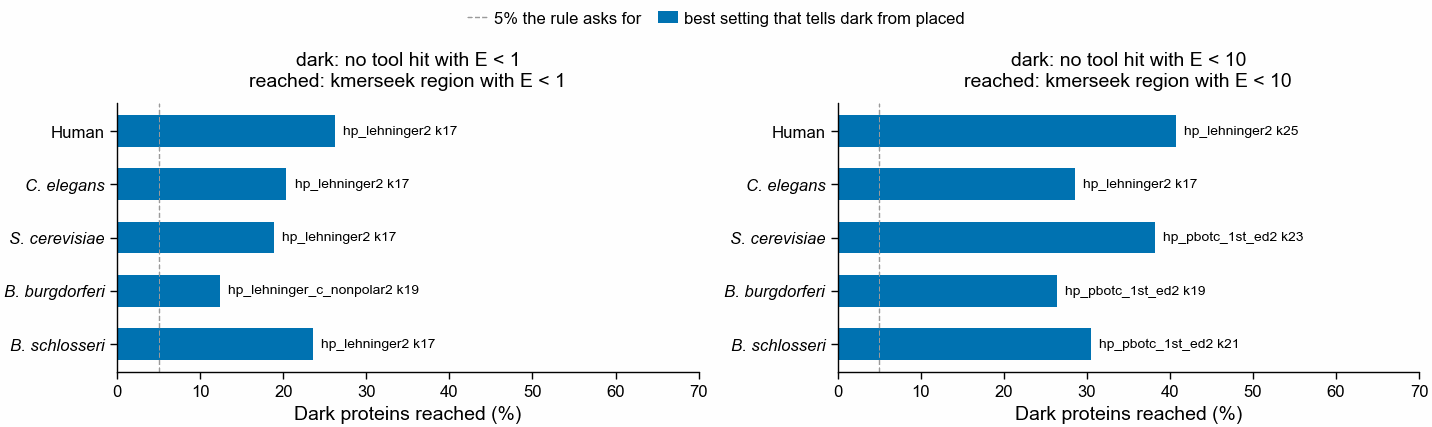

In [5]:
best = (
    reach_all.filter(pl.col("tells_dark_from_placed"))
    .sort("dark_share", descending=True)
    .group_by("tool_cutoff", "kmerseek_cutoff", "species", maintain_order=True)
    .head(1)
)
grid = pl.DataFrame(
    [
        {"tool_cutoff": float(t), "kmerseek_cutoff": float(k), "species": s}
        for t, k in CUTOFF_PAIRS
        for s in SPECIES
    ]
)
best = grid.join(
    best, on=["tool_cutoff", "kmerseek_cutoff", "species"], how="left"
).with_columns(pl.col("dark_share").fill_null(0.0), pl.col("dark_reached").fill_null(0))
print(
    best.select(
        "tool_cutoff",
        "kmerseek_cutoff",
        "species",
        "alphabet",
        "ksize",
        "dark_proteins",
        "dark_reached",
        pl.col("dark_share").round(3),
        "placed_reached",
        pl.col("placed_share").round(3),
    )
)

verdict = (
    best.group_by("tool_cutoff", "kmerseek_cutoff")
    .agg(
        (pl.col("dark_share") >= MIN_DARK_SHARE).sum().alias("species_with_candidates"),
        pl.len().alias("species"),
    )
    .sort("tool_cutoff")
)
verdict = verdict.with_columns(
    (pl.col("species_with_candidates") == pl.col("species")).alias("rule_met")
)
print(verdict)

fig, axs = pf.figure(
    pf.TWO_COLUMN_MM, 55, ncols=len(CUTOFF_PAIRS), sharex=True, squeeze=False
)
for c, (t, k) in enumerate(CUTOFF_PAIRS):
    ax = axs[0][c]
    d = best.filter(
        (pl.col("tool_cutoff") == t) & (pl.col("kmerseek_cutoff") == k)
    ).sort(pl.col("species").replace_strict(order))
    ys = list(range(len(SPECIES)))[::-1]
    ax.barh(
        ys,
        100 * d["dark_share"],
        color=pf.OKABE_ITO["blue"],
        height=0.6,
        label="best setting that tells dark from placed",
    )
    ax.axvline(
        100 * MIN_DARK_SHARE,
        color=pf.GREY,
        lw=0.5,
        ls="--",
        label=f"{100 * MIN_DARK_SHARE:g}% the rule asks for",
    )
    for y, share, a, kk in zip(ys, d["dark_share"], d["alphabet"], d["ksize"]):
        ax.text(
            100 * share + 1,
            y,
            f"{a} k{kk}" if a is not None else "none",
            va="center",
            fontsize=5,
        )
    ax.set_yticks(ys, [SPECIES_NAME[s] for s in d["species"]])
    for lab in ax.get_yticklabels():
        lab.set_fontstyle("normal" if lab.get_text() == "Human" else "italic")
    ax.set_xlim(0, 70)
    ax.set_xlabel(f"Dark proteins reached (%)")
    ax.set_title(
        f"dark: no tool hit with E < {t:g}\nreached: kmerseek region with E < {k:g}"
    )
pf.shared_legend(fig, ncol=2)
pf.save(fig, FIG / f"279_best_dark_reach_scaled{SCALED}_qfo_swissprot")

## 4. The dark proteins the best setting reaches with the smallest E-values

The five dark proteins with the smallest kmerseek region E-value under each species' best
setting (section 3), at each cutoff. These are the first ones to check by hand.

In [6]:
rows = []
for t, k in CUTOFF_PAIRS:
    flags = dark_flags(t)
    for r in best.filter(
        (pl.col("tool_cutoff") == t)
        & (pl.col("kmerseek_cutoff") == k)
        & pl.col("alphabet").is_not_null()
    ).iter_rows(named=True):
        e = (
            km.filter(
                (pl.col("species") == r["species"])
                & (pl.col("alphabet") == r["alphabet"])
                & (pl.col("ksize") == r["ksize"])
                & (pl.col("scaled") == SCALED)
                & (pl.col("min_region_evalue") < k)
            )
            .join(flags.filter(pl.col("dark")), on=["species", "accession"])
            .join(
                tool.select("species", "accession", "best_tool_evalue"),
                on=["species", "accession"],
            )
            .sort("min_region_evalue")
            .head(5)
        )
        rows.append(
            e.with_columns(
                pl.lit(float(t)).alias("tool_cutoff"),
                pl.lit(float(k)).alias("kmerseek_cutoff"),
            )
        )
examples = pl.concat(rows) if rows else pl.DataFrame()
if examples.height:
    print(
        examples.select(
            "tool_cutoff",
            "kmerseek_cutoff",
            "species",
            "alphabet",
            "ksize",
            "accession",
            "min_region_evalue",
            "best_tool_evalue",
        )
    )

┌─────────────┬─────────────────┬───────────┬──────────────────────────┬───────┬─────────────────────┬───────────────────┬──────────────────┐
│ tool_cutoff ┆ kmerseek_cutoff ┆ species   ┆ alphabet                 ┆ ksize ┆ accession           ┆ min_region_evalue ┆ best_tool_evalue │
│ ---         ┆ ---             ┆ ---       ┆ ---                      ┆ ---   ┆ ---                 ┆ ---               ┆ ---              │
│ f64         ┆ f64             ┆ str       ┆ str                      ┆ i64   ┆ str                 ┆ f64               ┆ f64              │
╞═════════════╪═════════════════╪═══════════╪══════════════════════════╪═══════╪═════════════════════╪═══════════════════╪══════════════════╡
│ 1.0         ┆ 1.0             ┆ human     ┆ hp_lehninger2            ┆ 17    ┆ Q86VQ0              ┆ 9.5720e-13        ┆ 1.3              │
│ 1.0         ┆ 1.0             ┆ human     ┆ hp_lehninger2            ┆ 17    ┆ Q96Q06              ┆ 5.1135e-9         ┆ 2.4              │
│ 1.0 

**What the example proteins are, from UniProt.**

Names, lengths and two UniProt annotations for the example proteins with a UniProt accession
(every species but *B. schlosseri*, whose gene models have none). *Compositional bias* marks
low-complexity or biased stretches (UniProt takes them from MobiDB-lite); *Repeat* marks
internal repeats. Either can give a kmerseek region a small E-value without a shared
ancestor, because the low-complexity mask was off. This table does not say whether the
kmerseek region sits in those stretches; that needs the region coordinates, which are in
the run's region files on Sherlock. Ten proteins per species cannot show a pattern; section
5 asks the same question of every protein.

The figure puts each example at its kmerseek region E-value (y) against the best E-value
any of the three tools found for it (x); proteins with no tool hit at all sit at the right
edge, marked "no hit".

The lookup is cached in `/Users/olga/data/invertebrate-dark-set/uniprot_cache/` and read
from there on re-runs.

38 example accessions, 38 found in UniProt
┌───────────┬──────────────────────────┬───────┬─────────────────────┬──────────┬─────────────────────────────────┬────────┬────────────────────┬─────────┬───────────────────┬──────────────────┐
│ species   ┆ alphabet                 ┆ ksize ┆ accession           ┆ gene     ┆ protein                         ┆ length ┆ compbias_stretches ┆ repeats ┆ min_region_evalue ┆ best_tool_evalue │
│ ---       ┆ ---                      ┆ ---   ┆ ---                 ┆ ---      ┆ ---                             ┆ ---    ┆ ---                ┆ ---     ┆ ---               ┆ ---              │
│ str       ┆ str                      ┆ i64   ┆ str                 ┆ str      ┆ str                             ┆ str    ┆ u32                ┆ u32     ┆ f64               ┆ f64              │
╞═══════════╪══════════════════════════╪═══════╪═════════════════════╪══════════╪═════════════════════════════════╪════════╪════════════════════╪═════════╪═══════════════════╪══

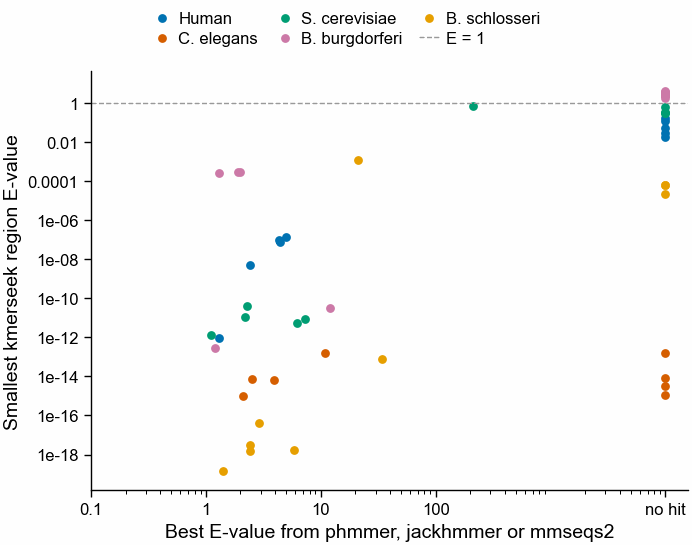

In [7]:
import urllib.parse
import urllib.request

CACHE = Path(
    "/Users/olga/data/invertebrate-dark-set/uniprot_cache/279_example_proteins.tsv"
)
accs = sorted(
    set(
        examples.filter(~pl.col("accession").str.starts_with("FUN"))[
            "accession"
        ].to_list()
    )
)
if not CACHE.exists() or set(
    pl.read_csv(CACHE, separator="\t")["Entry"].to_list()
) != set(accs):
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    query = " OR ".join(f"accession:{a}" for a in accs)
    url = "https://rest.uniprot.org/uniprotkb/search?" + urllib.parse.urlencode(
        {
            "query": query,
            "fields": "accession,gene_primary,protein_name,length,ft_compbias,ft_repeat",
            "format": "tsv",
            "size": 500,
        }
    )
    text = urllib.request.urlopen(url, timeout=120).read().decode()
    if not text.startswith("Entry\t"):
        raise ValueError(f"UniProt did not return a table: {text[:200]}")
    CACHE.write_text(text)
uni = pl.read_csv(CACHE, separator="\t", infer_schema_length=0).rename(
    {
        "Entry": "accession",
        "Gene Names (primary)": "gene",
        "Protein names": "protein",
        "Length": "length",
        "Compositional bias": "compbias",
        "Repeat": "repeat",
    }
)
uni = uni.with_columns(
    pl.col("compbias")
    .fill_null("")
    .str.count_matches("COMPBIAS")
    .alias("compbias_stretches"),
    pl.col("repeat").fill_null("").str.count_matches("REPEAT").alias("repeats"),
    pl.col("protein").str.slice(0, 45),
)
print(f"{len(accs)} example accessions, {uni.height} found in UniProt")
ex = examples.join(
    uni.select(
        "accession", "gene", "protein", "length", "compbias_stretches", "repeats"
    ),
    on="accession",
    how="left",
).unique(["species", "accession"], keep="first", maintain_order=True)
print(
    ex.select(
        "species",
        "alphabet",
        "ksize",
        "accession",
        "gene",
        "protein",
        "length",
        "compbias_stretches",
        "repeats",
        "min_region_evalue",
        "best_tool_evalue",
    )
)

NO_HIT = 1e4  # x position for proteins with no tool hit at all
pts = ex.with_columns(pl.col("best_tool_evalue").fill_null(NO_HIT))
SPECIES_COLOUR = dict(
    zip(
        SPECIES,
        [
            pf.OKABE_ITO[c]
            for c in ["blue", "vermillion", "bluish_green", "reddish_purple", "orange"]
        ],
    )
)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 70)
for s in SPECIES:
    d = pts.filter(pl.col("species") == s)
    ax.scatter(
        d["best_tool_evalue"],
        d["min_region_evalue"],
        s=10,
        lw=0,
        color=SPECIES_COLOUR[s],
        label=SPECIES_NAME[s],
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([1e-1, 1, 10, 100, NO_HIT], ["0.1", "1", "10", "100", "no hit"])
ax.set_xlabel("Best E-value from phmmer, jackhmmer or mmseqs2")
ax.set_ylabel("Smallest kmerseek region E-value")
ax.yaxis.set_major_locator(plt.matplotlib.ticker.LogLocator(base=10, numticks=12))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(plt.matplotlib.ticker.NullFormatter())
ax.axhline(1, color=pf.GREY, lw=0.5, ls="--", label="E = 1")
print(
    pts.group_by("species")
    .agg(
        pl.len().alias("examples"),
        (pl.col("best_tool_evalue") == NO_HIT).sum().alias("no_tool_hit"),
        pl.col("min_region_evalue").min().alias("smallest_kmerseek_evalue"),
    )
    .sort(pl.col("species").replace_strict(order))
)
pf.shared_legend(fig, ncol=3)
pf.save(fig, FIG / f"279_example_dark_proteins_kmerseek_vs_tool_evalue_scaled{SCALED}")

## 5. Are the dark proteins kmerseek reaches different from the ones it misses?

If kmerseek reaches dark proteins through low-complexity stretches, repeats or
transmembrane helices rather than shared ancestry, the dark proteins it reaches should carry
those features more often than the dark proteins it misses. An H/P alphabet reads a
transmembrane helix as a long run of H, so helices are a likely cause for these alphabets
(notebook 240 held transmembrane segments out of its Pfam test for this reason).

For each species with UniProt accessions and each cutoff, three groups: placed proteins, dark
proteins the best setting of section 3 misses, and dark proteins it reaches. For each group,
the share that UniProt marks with at least one compositional-bias stretch, at least one
repeat, or at least one transmembrane helix. The UniProt annotation of each whole reference
proteome is downloaded once and cached in `/Users/olga/data/invertebrate-dark-set/uniprot_cache/`.

Proteins without a UniProt annotation row (left out of the shares):
┌──────────┬─────────────┬───────────────┬──────────┐
│ species  ┆ tool_cutoff ┆ no_annotation ┆ proteins │
│ ---      ┆ ---         ┆ ---           ┆ ---      │
│ str      ┆ f64         ┆ u32           ┆ u32      │
╞══════════╪═════════════╪═══════════════╪══════════╡
│ human    ┆ 1.0         ┆ 150           ┆ 20600    │
│ worm     ┆ 1.0         ┆ 225           ┆ 19819    │
│ yeast    ┆ 1.0         ┆ 0             ┆ 6049     │
│ borrelia ┆ 1.0         ┆ 0             ┆ 1291     │
│ human    ┆ 10.0        ┆ 150           ┆ 20600    │
│ worm     ┆ 10.0        ┆ 225           ┆ 19819    │
│ yeast    ┆ 10.0        ┆ 0             ┆ 6049     │
│ borrelia ┆ 10.0        ┆ 0             ┆ 1291     │
└──────────┴─────────────┴───────────────┴──────────┘
┌─────────────┬─────────────────┬──────────┬──────────────────────────────┬───────────────┬──────────┬──────────┬────────┬──────────┐
│ tool_cutoff ┆ kmerseek_cutoff ┆ species 

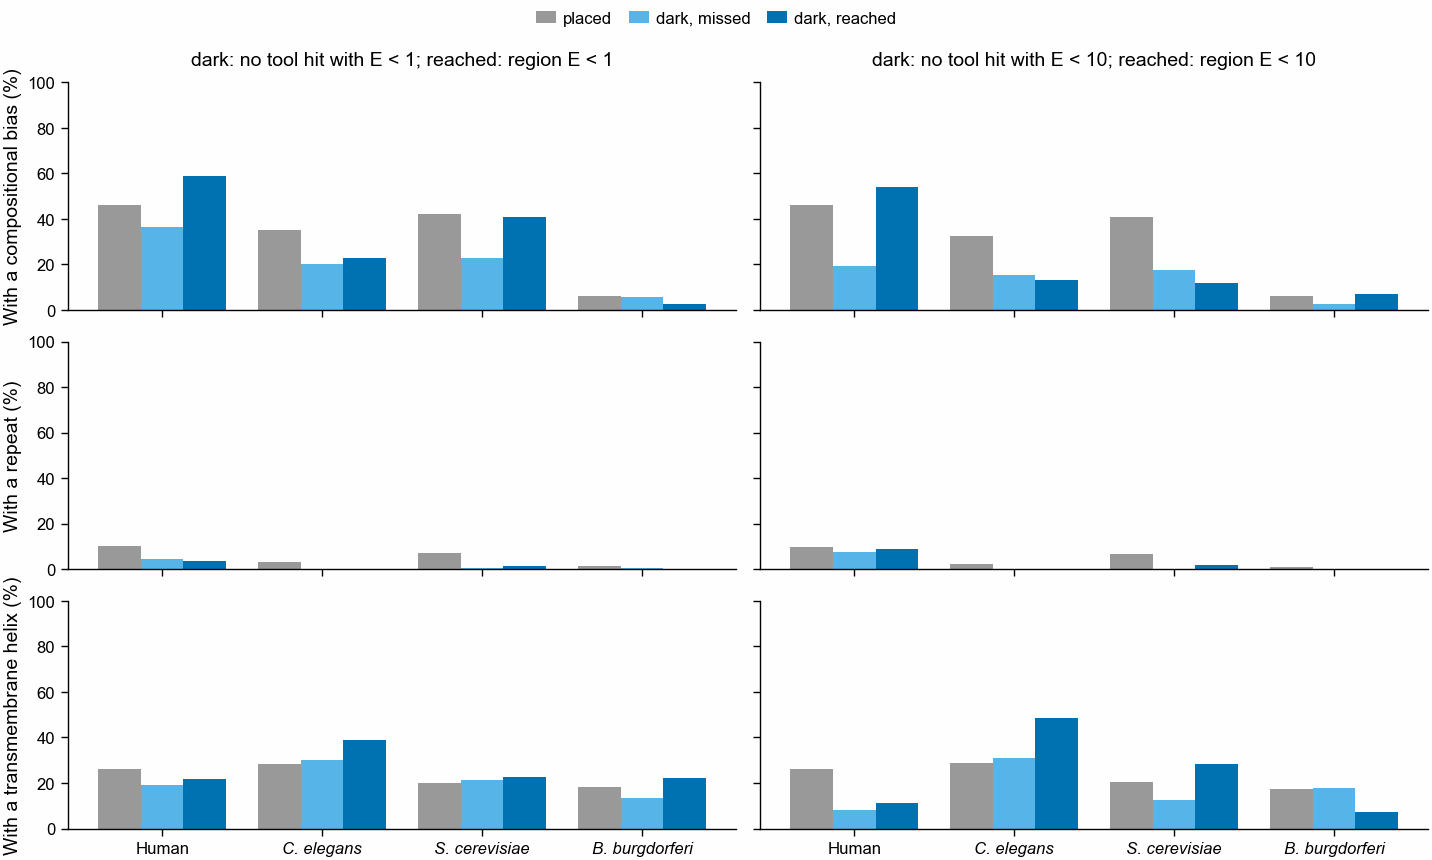

In [8]:
PROTEOMES = {
    "human": "UP000005640",
    "worm": "UP000001940",
    "yeast": "UP000002311",
    "borrelia": "UP000001807",
}
CACHE_DIR = Path("/Users/olga/data/invertebrate-dark-set/uniprot_cache")
FEATURES = {
    "compbias": "compositional bias",
    "repeat": "repeat",
    "transmem": "transmembrane helix",
}
ann = []
for s, up in PROTEOMES.items():
    f = CACHE_DIR / f"{up}_compbias_repeat.tsv"
    if not f.exists():
        url = "https://rest.uniprot.org/uniprotkb/stream?" + urllib.parse.urlencode(
            {
                "query": f"proteome:{up}",
                "fields": "accession,ft_compbias,ft_repeat,ft_transmem",
                "format": "tsv",
            }
        )
        text = urllib.request.urlopen(url, timeout=600).read().decode()
        if not text.startswith("Entry\t"):
            raise ValueError(f"UniProt did not return a table for {up}: {text[:200]}")
        f.write_text(text)
    a = pl.read_csv(f, separator="\t", infer_schema_length=0).rename(
        {
            "Entry": "accession",
            "Compositional bias": "compbias",
            "Repeat": "repeat",
            "Transmembrane": "transmem",
        }
    )
    ann.append(
        a.select(
            "accession",
            *[pl.col(c).is_not_null() & (pl.col(c) != "") for c in FEATURES],
        ).with_columns(pl.lit(s).alias("species"))
    )
ann = pl.concat(ann)

groups = []
for t, k in CUTOFF_PAIRS:
    flags = dark_flags(t)
    for r in best.filter(
        (pl.col("tool_cutoff") == t)
        & (pl.col("kmerseek_cutoff") == k)
        & pl.col("species").is_in(list(PROTEOMES))
        & pl.col("alphabet").is_not_null()
    ).iter_rows(named=True):
        reached = set(
            km.filter(
                (pl.col("species") == r["species"])
                & (pl.col("alphabet") == r["alphabet"])
                & (pl.col("ksize") == r["ksize"])
                & (pl.col("scaled") == SCALED)
                & (pl.col("min_region_evalue") < k)
            )["accession"].to_list()
        )
        g = (
            flags.filter(pl.col("species") == r["species"])
            .with_columns(
                pl.when(~pl.col("dark"))
                .then(pl.lit("placed"))
                .when(pl.col("accession").is_in(list(reached)))
                .then(pl.lit("dark, reached"))
                .otherwise(pl.lit("dark, missed"))
                .alias("group")
            )
            .join(ann, on=["species", "accession"], how="left")
        )
        groups.append(
            g.with_columns(
                pl.lit(float(t)).alias("tool_cutoff"),
                pl.lit(float(k)).alias("kmerseek_cutoff"),
                pl.lit(f"{r['alphabet']} k{r['ksize']}").alias("setting"),
            )
        )
groups = pl.concat(groups)
print("Proteins without a UniProt annotation row (left out of the shares):")
print(
    groups.group_by("species", "tool_cutoff")
    .agg(
        pl.col("compbias").is_null().sum().alias("no_annotation"),
        pl.len().alias("proteins"),
    )
    .sort("tool_cutoff", pl.col("species").replace_strict(order))
)
GROUPS = ["placed", "dark, missed", "dark, reached"]
shares = (
    groups.filter(pl.col("compbias").is_not_null())
    .group_by("tool_cutoff", "kmerseek_cutoff", "species", "setting", "group")
    .agg(pl.len().alias("proteins"), *[pl.col(c).mean().alias(c) for c in FEATURES])
    .sort(
        "tool_cutoff",
        pl.col("species").replace_strict(order),
        pl.col("group").replace_strict({g: i for i, g in enumerate(GROUPS)}),
    )
)
print(shares.with_columns(pl.col(list(FEATURES)).round(3)))

GROUP_COLOUR = {
    "placed": pf.GREY,
    "dark, missed": pf.OKABE_ITO["sky_blue"],
    "dark, reached": pf.OKABE_ITO["blue"],
}
sp = [s for s in SPECIES if s in PROTEOMES]
fig, axs = pf.figure(
    pf.TWO_COLUMN_MM,
    110,
    nrows=len(FEATURES),
    ncols=len(CUTOFF_PAIRS),
    sharex=True,
    sharey="row",
    squeeze=False,
)
w = 0.8 / len(GROUPS)
for c, (t, k) in enumerate(CUTOFF_PAIRS):
    for r_i, (feat, feat_name) in enumerate(FEATURES.items()):
        ax = axs[r_i][c]
        for j, g in enumerate(GROUPS):
            d = shares.filter((pl.col("tool_cutoff") == t) & (pl.col("group") == g))
            xs = [sp.index(s) + (j - 1) * w for s in d["species"]]
            ax.bar(xs, 100 * d[feat], width=w, color=GROUP_COLOUR[g], label=g)
        ax.set_ylim(0, 100)
        if c == 0:
            ax.set_ylabel(f"With a {feat_name} (%)")
        if r_i == 0:
            ax.set_title(f"dark: no tool hit with E < {t:g}; reached: region E < {k:g}")
        ax.set_xticks(range(len(sp)), [SPECIES_NAME[s] for s in sp])
        for lab in ax.get_xticklabels():
            lab.set_fontstyle("normal" if lab.get_text() == "Human" else "italic")
pf.shared_legend(fig, ncol=3)
pf.save(fig, FIG / f"279_dark_reached_vs_missed_uniprot_features_scaled{SCALED}")

# Summary and Conclusions

## Background

The dark set is the proteins phmmer, jackhmmer and mmseqs2 all fail to place in Swiss-Prot
with the query's own clade removed. This notebook asks how many of them kmerseek puts a
region on, at E < 1 and E < 10 for both the tools and kmerseek, in human, *C. elegans*,
*S. cerevisiae*, *B. burgdorferi* and *B. schlosseri*, using the finished dark-set midi run
(PR 57). Every number comes from filtering per-protein E-values; nothing was searched again.

## Summary and Conclusions

* Loosening the tool cutoff shrinks the human dark set from 3_103 proteins (15.1%) at
  E < 0.001 to 1_696 (8.2%) at E < 1 and 442 (2.1%) at E < 10.
* At E < 1, the best kmerseek setting reaches 12-26% of dark proteins against 38-73% of
  placed proteins; hp_lehninger2 k17 is that setting in four of five species.
* At E < 10, the best settings reach 26-41% of dark proteins against 61-82% of placed
  proteins, and every one is an H/P (hydrophobic/polar) alphabet.
* The decision rule is met at both cutoffs: in all five species a setting that reaches
  placed proteins at least twice as often as dark ones reaches at least 5% of dark proteins.
* In human, 58.7% of the dark proteins hp_lehninger2 k17 reaches at E < 1 carry a UniProt
  compositional-bias stretch, against 36.2% of the dark proteins it misses.
* In *C. elegans*, 48.4% of the dark proteins reached at E < 10 have a transmembrane helix,
  against 30.8% of those missed; at E < 1 all five top examples are serpentine receptors.
* So the candidates cannot go to the structure check as they are: the low-complexity mask was
  off, and in human and worm the reached dark proteins lean towards biased sequence and helices.

## Analysis Details

The dark set at each cutoff comes from each protein's smallest phmmer, jackhmmer and mmseqs2
hit E-value; the tools ran with a reporting cutoff of 10, so every hit below 10 is kept.
kmerseek reach comes from each protein's smallest region E-value per setting. Section 2 draws
every alphabet and k-size at scaled 1: at E < 1 nearly all settings reach far more placed
than dark proteins; at E < 10 many sit on or near the "twice" line. Section 3 picks, per
species and cutoff, the setting with the largest dark share among those that reach placed
proteins at least twice as often. Section 4 lists the five dark proteins with the smallest
kmerseek E-value under that setting; several have no tool hit at all but a kmerseek region
E-value near 1e-15 (worm srh-97, sre-41). Section 5 compares UniProt features of dark
proteins reached against dark proteins missed. The pattern is not the same everywhere: in
*S. cerevisiae* reached dark proteins carry compositional bias more often at E < 1 (40.9%
against 22.6%) but less often at E < 10 (11.7% against 17.5%), and *B. burgdorferi* has too
few dark proteins (53 at E < 10) to read. UniProt features are whole-protein marks; whether a
kmerseek region sits inside a biased stretch or a helix is not checked here.

Next step: read the region coordinates for the reached dark proteins from the run's region
files on Sherlock and drop regions that overlap a compositional-bias stretch or a
transmembrane helix, then recount. That is a filter over existing files, not a new search.

## Supplementary Information

- Cutoffs and the scaled setting are set in the first code cell (`CUTOFF_PAIRS`, `SCALED`).
- A protein counts below a cutoff when its E-value is strictly less than it. The pipeline's
  own dark set uses E <= 0.001, so one human and one *B. schlosseri* protein whose best hit is
  exactly 0.001 differ.
- Run: `runs/ladder-0.4-midi`, finished 2026-10-12, image `olgabot/kmerseek:0.4.0-rc5`,
  pipeline commit e3808d1; export `tools/export-protein-evalues` at ac5e4f9 (PR 57).
- Settings without a Karlin-Altschul fit (26-30 per species at scaled 1) have no E-values
  and are not drawn.
- Ten *B. schlosseri* ids contain a comma; the export maps them back to the full id, while
  the pipeline's own gain step misses them.
- Output table: `tables/279_dark_set_kmerseek_reach_scaled1_qfo_swissprot.csv`.

## References

- [PR 57](https://github.com/seanome/2024-kmerseek-analysis/pull/57): the dark-set pipeline
  and the export script.
- Notebook 274 ([PR 101](https://github.com/seanome/2024-kmerseek-analysis/pull/101)): the
  k-size range per alphabet.
- Notebook 240: Pfam dose-response with transmembrane instances held out.
- UniProt REST API, compositional bias (MobiDB-lite), repeat and transmembrane features,
  read 2026-10-12. https://rest.uniprot.org

In [9]:
summary_md = r"""
# Summary and Conclusions

## Background

The dark set is the proteins phmmer, jackhmmer and mmseqs2 all fail to place in Swiss-Prot
with the query's own clade removed. This notebook asks how many of them kmerseek puts a
region on, at E < 1 and E < 10 for both the tools and kmerseek, in human, *C. elegans*,
*S. cerevisiae*, *B. burgdorferi* and *B. schlosseri*, using the finished dark-set midi run
(PR 57). Every number comes from filtering per-protein E-values; nothing was searched again.

## Summary and Conclusions

* Loosening the tool cutoff shrinks the human dark set from 3_103 proteins (15.1%) at
  E < 0.001 to 1_696 (8.2%) at E < 1 and 442 (2.1%) at E < 10.
* At E < 1, the best kmerseek setting reaches 12-26% of dark proteins against 38-73% of
  placed proteins; hp_lehninger2 k17 is that setting in four of five species.
* At E < 10, the best settings reach 26-41% of dark proteins against 61-82% of placed
  proteins, and every one is an H/P (hydrophobic/polar) alphabet.
* The decision rule is met at both cutoffs: in all five species a setting that reaches
  placed proteins at least twice as often as dark ones reaches at least 5% of dark proteins.
* In human, 58.7% of the dark proteins hp_lehninger2 k17 reaches at E < 1 carry a UniProt
  compositional-bias stretch, against 36.2% of the dark proteins it misses.
* In *C. elegans*, 48.4% of the dark proteins reached at E < 10 have a transmembrane helix,
  against 30.8% of those missed; at E < 1 all five top examples are serpentine receptors.
* So the candidates cannot go to the structure check as they are: the low-complexity mask was
  off, and in human and worm the reached dark proteins lean towards biased sequence and helices.

## Analysis Details

The dark set at each cutoff comes from each protein's smallest phmmer, jackhmmer and mmseqs2
hit E-value; the tools ran with a reporting cutoff of 10, so every hit below 10 is kept.
kmerseek reach comes from each protein's smallest region E-value per setting. Section 2 draws
every alphabet and k-size at scaled 1: at E < 1 nearly all settings reach far more placed
than dark proteins; at E < 10 many sit on or near the "twice" line. Section 3 picks, per
species and cutoff, the setting with the largest dark share among those that reach placed
proteins at least twice as often. Section 4 lists the five dark proteins with the smallest
kmerseek E-value under that setting; several have no tool hit at all but a kmerseek region
E-value near 1e-15 (worm srh-97, sre-41). Section 5 compares UniProt features of dark
proteins reached against dark proteins missed. The pattern is not the same everywhere: in
*S. cerevisiae* reached dark proteins carry compositional bias more often at E < 1 (40.9%
against 22.6%) but less often at E < 10 (11.7% against 17.5%), and *B. burgdorferi* has too
few dark proteins (53 at E < 10) to read. UniProt features are whole-protein marks; whether a
kmerseek region sits inside a biased stretch or a helix is not checked here.

Next step: read the region coordinates for the reached dark proteins from the run's region
files on Sherlock and drop regions that overlap a compositional-bias stretch or a
transmembrane helix, then recount. That is a filter over existing files, not a new search.

## Supplementary Information

- Cutoffs and the scaled setting are set in the first code cell (`CUTOFF_PAIRS`, `SCALED`).
- A protein counts below a cutoff when its E-value is strictly less than it. The pipeline's
  own dark set uses E <= 0.001, so one human and one *B. schlosseri* protein whose best hit is
  exactly 0.001 differ.
- Run: `runs/ladder-0.4-midi`, finished 2026-10-12, image `olgabot/kmerseek:0.4.0-rc5`,
  pipeline commit e3808d1; export `tools/export-protein-evalues` at ac5e4f9 (PR 57).
- Settings without a Karlin-Altschul fit (26-30 per species at scaled 1) have no E-values
  and are not drawn.
- Ten *B. schlosseri* ids contain a comma; the export maps them back to the full id, while
  the pipeline's own gain step misses them.
- Output table: `tables/279_dark_set_kmerseek_reach_scaled1_qfo_swissprot.csv`.

## References

- [PR 57](https://github.com/seanome/2024-kmerseek-analysis/pull/57): the dark-set pipeline
  and the export script.
- Notebook 274 ([PR 101](https://github.com/seanome/2024-kmerseek-analysis/pull/101)): the
  k-size range per alphabet.
- Notebook 240: Pfam dose-response with transmembrane instances held out.
- UniProt REST API, compositional bias (MobiDB-lite), repeat and transmembrane features,
  read 2026-10-12. https://rest.uniprot.org
"""
print(summary_md)


# Summary and Conclusions

## Background

The dark set is the proteins phmmer, jackhmmer and mmseqs2 all fail to place in Swiss-Prot
with the query's own clade removed. This notebook asks how many of them kmerseek puts a
region on, at E < 1 and E < 10 for both the tools and kmerseek, in human, *C. elegans*,
*S. cerevisiae*, *B. burgdorferi* and *B. schlosseri*, using the finished dark-set midi run
(PR 57). Every number comes from filtering per-protein E-values; nothing was searched again.

## Summary and Conclusions

* Loosening the tool cutoff shrinks the human dark set from 3_103 proteins (15.1%) at
  E < 0.001 to 1_696 (8.2%) at E < 1 and 442 (2.1%) at E < 10.
* At E < 1, the best kmerseek setting reaches 12-26% of dark proteins against 38-73% of
  placed proteins; hp_lehninger2 k17 is that setting in four of five species.
* At E < 10, the best settings reach 26-41% of dark proteins against 61-82% of placed
  proteins, and every one is an H/P (hydrophobic/polar) alphabet.
* The dec